<a href="https://colab.research.google.com/github/raminass/Software-Project/blob/main/pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Author**: Rami Nasser (raminass@gmail.com), Yael Kupershmidt (kupershmidt@mail.tau.ac.il)


# Earlier

*   Numpy
*   Scipy
*   Matplotlib

# Today

*   Pandas









# Pandas

**Learning Objectives:**
  * Gain an introduction to the `DataFrame` and `Series` data structures of the *pandas* library
  * Access and manipulate data within a `DataFrame` and `Series`
  * Import CSV data into a *pandas* `DataFrame`


[*pandas*](https://pandas.pydata.org/) is a column-oriented data analysis API. It's a great tool for handling and analyzing input data, and many ML frameworks support *pandas* data structures as inputs.
Although a comprehensive introduction to the *pandas* API would span many pages, the core concepts are fairly straightforward, and we'll present them below. For a more complete reference, the [*pandas* docs site](https://pandas.pydata.org/docs/) contains extensive documentation and many tutorials.

## Setup

Install

The course Docker image already has pandas installed (see `requirements.txt`). On another machine, install it from a terminal with `pip install pandas`.

Import - External Package

In [1]:
import pandas as pd

The primary data structures in *pandas* are implemented as two classes:

  * **`DataFrame`**, which you can imagine as a relational data table, with rows and named columns.
  * **`Series`**, which is a single column. A `DataFrame` contains one or more `Series` and a name for each `Series`.

The data frame is a commonly used abstraction for data manipulation. Similar implementations exist in [Spark](https://spark.apache.org/) and [R](https://www.r-project.org/about.html).

## Series

One way to create a `Series` is to construct a `Series` object. For example:

In [2]:
pd.Series(['San Francisco', 'San Jose', 'Sacramento'])

0    San Francisco
1         San Jose
2       Sacramento
dtype: str

## Creating Data

`DataFrame` objects can be created by passing a `dict` mapping `string` column names to their respective `Series`. If the `Series` don't match in length, missing values are filled with special [NA/NaN](https://pandas.pydata.org/docs/user_guide/missing_data.html) values. Example:

In [3]:
city_names = pd.Series(['San Francisco', 'San Jose', 'Sacramento'])
population = pd.Series([852469, 1015785, 485199])
cities = pd.DataFrame({'City name': city_names, 'Population': population})
print("DataFrame built from a dict of two Series:")
print(cities)
print()

# Missing values: population now has only 2 values for 3 cities
population = pd.Series([852469, 1015785])
cities = pd.DataFrame({'City name': city_names, 'Population': population})
print("Population has no value for the third city, so it is filled with NaN:")
print(cities)
print("NaN is a float, so the Population column becomes:", cities['Population'].dtype)

DataFrame built from a dict of two Series:
       City name  Population
0  San Francisco      852469
1       San Jose     1015785
2     Sacramento      485199

Population has no value for the third city, so it is filled with NaN:
       City name  Population
0  San Francisco    852469.0
1       San Jose   1015785.0
2     Sacramento         NaN
NaN is a float, so the Population column becomes: float64


A DataFrame is a table (like an Excel sheet). Each row is a record and each column holds one kind of value.

In the `city_names` / `Population` example above, the dictionary gave the **column** labels, but the **row** labels are just a count from 0 (0, 1, 2, ...). Sometimes this is OK, but often we want to choose these labels ourselves.

The list of row labels used in a DataFrame is known as an **Index**. We can set it with the `index` parameter of the constructor:

In [4]:
# Student list
students = pd.DataFrame({'Name': ['Ross', 'Monica','Chandler'],
              'Last Name': ['Geller', 'Geller','Bing'],
              'GPA': [98, 99, 90]},
               index=['id1', 'id2','id3'])
students

,Name,Last Name,GPA
id1,Ross,Geller,98
id2,Monica,Geller,99
id3,Chandler,Bing,90


### Changing a value

In pandas 3, **Copy-on-Write** is always on: every selection behaves like an independent copy.
So *chained* indexing such as `students['Name']['id1'] = ...` first creates a new Series (`students['Name']`), changes **that copy**, and leaves `students` unchanged. pandas warns with `ChainedAssignmentError`:

In [5]:
students['Name']['id1'] = 'Joey'   # does NOT change students
students

/tmp/ipykernel_1950130/4226053823.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  students['Name']['id1'] = 'Joey'   # does NOT change students


,Name,Last Name,GPA
id1,Ross,Geller,98
id2,Monica,Geller,99
id3,Chandler,Bing,90


Use a single `.loc[row, column]` assignment instead:

In [6]:
print("students before the assignment:")
print(students)
print()

students.loc['id1', 'Name'] = 'Joey'
print("students after students.loc['id1', 'Name'] = 'Joey', the Name of id1 has changed:")
print(students)

students before the assignment:
         Name Last Name  GPA
id1      Ross    Geller   98
id2    Monica    Geller   99
id3  Chandler      Bing   90

students after students.loc['id1', 'Name'] = 'Joey', the Name of id1 has changed:
         Name Last Name  GPA
id1      Joey    Geller   98
id2    Monica    Geller   99
id3  Chandler      Bing   90


## Reading Data

Being able to create a DataFrame or Series by hand is handy. But, most of the time, we won't actually be creating our own data by hand. Instead, we'll be working with data that already exists.

Data can be stored in any of a number of different forms and formats. By far the most basic of these is the humble CSV file. When you open a CSV file you get something that looks like this:

```csv
A,B,C,
30,21,9,
35,34,1,
41,11,11
```



So a CSV file is a table of values separated by commas. Hence the name: "Comma-Separated Values", or CSV.

Let's now set aside our toy datasets and see what a real dataset looks like when we read it into a DataFrame. We'll use the pd.read_csv() function to read the data into a DataFrame.

Reading from web directly:

In [7]:
houses = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/california_housing_train.csv")

We can use the shape attribute to check how large the resulting DataFrame is:



In [8]:
print(houses.shape)
houses

(17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0


We can examine the contents of the resultant DataFrame using the head()

command, which grabs the first five rows:

In [9]:
# arg the desired number of rows
houses.head(8)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
5,-114.58,33.63,29.0,1387.0,236.0,671.0,239.0,3.3438,74000.0
6,-114.58,33.61,25.0,2907.0,680.0,1841.0,633.0,2.6768,82400.0
7,-114.59,34.83,41.0,812.0,168.0,375.0,158.0,1.7083,48500.0


Statistical overview of the dataset:

In [10]:
houses.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
from IPython.display import display   # display() shows a DataFrame as a formatted table

print("Data type of each column:")
print(houses.dtypes)

print("\n5 random rows, random_state makes the choice repeatable:")
display(houses.sample(5, random_state=0))

print("Filtering: the first 5 houses whose median age is above 50 years:")
display(houses[houses['housing_median_age'] > 50].head(5))

Data type of each column:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
dtype: object

5 random rows, random_state makes the choice repeatable:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
3873,-117.95,33.84,18.0,3418.0,815.0,1961.0,773.0,3.6500,171400.0
3625,-117.92,34.08,36.0,1479.0,251.0,741.0,245.0,4.2986,189600.0
3028,-117.80,33.83,17.0,2971.0,350.0,1180.0,346.0,11.1228,500001.0
13814,-122.01,36.98,47.0,2403.0,517.0,1144.0,455.0,2.5954,229400.0
15398,-122.30,38.25,18.0,3548.0,880.0,1476.0,699.0,3.7188,163400.0


Filtering: the first 5 houses whose median age is above 50 years:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
325,-116.88,34.08,52.0,3419.0,777.0,710.0,265.0,3.9028,128600.0
1011,-117.10,32.76,52.0,2606.0,426.0,883.0,380.0,4.2813,270800.0
1074,-117.11,32.77,52.0,1506.0,233.0,478.0,240.0,4.3875,300000.0
1075,-117.11,32.77,52.0,1484.0,224.0,498.0,223.0,6.6053,331400.0
1103,-117.11,32.67,52.0,280.0,71.0,217.0,71.0,1.4844,83300.0


Reading from local storage:

In [12]:
from pathlib import Path

# A copy of the dataset is in the repository (data/tips.csv); fall back to the web copy if it is missing.
TIPS_PATH = Path('data/tips.csv')
TIPS_URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv'
tips = pd.read_csv(TIPS_PATH if TIPS_PATH.exists() else TIPS_URL)

print("Shape of tips:", tips.shape)
tips.head()

Shape of tips: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Accessing Data

Every column of a DataFrame is a **`Series`**. There are two ways to get one:

* attribute access: `tips.total_bill`
* indexing: `tips['total_bill']`

Both return the same Series. Prefer `[]`: it also works when the column name has a space, and when the name clashes with a DataFrame attribute. The tips data has such a column: `tips.size` is the number of cells in the table, while `tips['size']` is the column.

A Series is like a dictionary from row label to value, so one more `[]` gives a single value, and `.unique()` lists the distinct values. Text columns have dtype `str` in pandas 3; older tutorials show `object` instead.

In [13]:
print("tips.total_bill, first 3 rows:")
print(tips.total_bill.head(3))
print("tips['total_bill'] is the same Series:")
print(tips['total_bill'].head(3))
print("type of tips['time']:", type(tips['time']))
print()

print("value of tips['time'] at row 200:", tips['time'][200])
print("distinct values of tips['time']:")
print(tips['time'].unique())
print()

print("tips.size is the number of cells, 244 rows times 7 columns:", tips.size)
print("tips['size'] is the column, first 3 rows:")
print(tips['size'].head(3))

tips.total_bill, first 3 rows:
0    16.99
1    10.34
2    21.01
Name: total_bill, dtype: float64
tips['total_bill'] is the same Series:
0    16.99
1    10.34
2    21.01
Name: total_bill, dtype: float64
type of tips['time']: <class 'pandas.Series'>

value of tips['time'] at row 200: Lunch
distinct values of tips['time']:
<StringArray>
['Dinner', 'Lunch']
Length: 2, dtype: str

tips.size is the number of cells, 244 rows times 7 columns: 1708
tips['size'] is the column, first 3 rows:
0    2
1    3
2    3
Name: size, dtype: int64


## Indexing

`tips.total_bill` and `tips['total_bill']` select **columns**. To select **rows**, or rows and columns together, pandas has two accessors. Both take `[rows, columns]`, rows first:

| Accessor | Selects by | Slice end `a:b` | Example |
|---|---|---|---|
| `iloc` | **position**: 0, 1, 2, ... like a Python list | excluded | `tips.iloc[103:107, 0]` gives positions 103 to 106 |
| `loc` | **label**: the values of the index | **included** | `tips.loc[103:107, 'tip']` gives labels 103 to 107 |

More info in the documentation: [indexing and selection](https://pandas.pydata.org/docs/user_guide/indexing.html).

### 1. `[]` selects columns, not rows

Plain `[]` on a DataFrame always looks up **column labels**, so `tips[-2]` does not give the second last row: it raises a `KeyError`, because there is no column named `-2`. The cell catches the error with `try` / `except` and prints it.

In [14]:
try:
    tips[-2]
except KeyError as err:
    print(f"tips[-2] fails with {type(err).__name__}: {err}, there is no column named -2")

tips[-2] fails with KeyError: -2, there is no column named -2


### 2. `iloc`: select by position

In [15]:
print("tips.iloc[-2], the second last row:")
print(tips.iloc[-2])
print()
print("tips.iloc[:, 0], the first column, first 3 rows:")
print(tips.iloc[:, 0].head(3))
print()
print("tips.iloc[103:107, 0], positions 103 to 106, the end is excluded:")
print(tips.iloc[103:107, 0])

tips.iloc[-2], the second last row:
total_bill     17.82
tip             1.75
sex             Male
smoker            No
day              Sat
time          Dinner
size               2
Name: 242, dtype: object

tips.iloc[:, 0], the first column, first 3 rows:
0    16.99
1    10.34
2    21.01
Name: total_bill, dtype: float64

tips.iloc[103:107, 0], positions 103 to 106, the end is excluded:
103    22.42
104    20.92
105    15.36
106    20.49
Name: total_bill, dtype: float64


### 3. `loc`: select by label

Compare with the last `iloc` example: the same numbers `103:107`, but `loc` includes the end.

In [16]:
print("tips.loc[103:107, 'tip'], labels 103 to 107, the end is included:")
print(tips.loc[103:107, 'tip'])

tips.loc[103:107, 'tip'], labels 103 to 107, the end is included:
103    3.48
104    4.08
105    1.64
106    4.06
107    4.29
Name: tip, dtype: float64


### 4. `set_index`: use a column as the row labels

After `set_index('day')`, the row labels are day names, so `loc` can select all rows of one day.

In [17]:
df = tips.set_index('day')
print("df = tips.set_index('day'), first 3 rows:")
print(df.head(3))
print()
print("df.loc['Sun', 'total_bill'], the bills of Sunday rows, first 3:")
print(df.loc['Sun', 'total_bill'].head(3))

df = tips.set_index('day'), first 3 rows:
     total_bill   tip     sex smoker    time  size
day                                               
Sun       16.99  1.01  Female     No  Dinner     2
Sun       10.34  1.66    Male     No  Dinner     3
Sun       21.01  3.50    Male     No  Dinner     3

df.loc['Sun', 'total_bill'], the bills of Sunday rows, first 3:
day
Sun    16.99
Sun    10.34
Sun    21.01
Name: total_bill, dtype: float64


## Manipulating Data

You may apply Python's basic arithmetic operations to `Series`. For example:

In [18]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [19]:
tips['new_calc'] = tips.total_bill / 10

In [20]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size,new_calc
0,16.99,1.01,Female,No,Sun,Dinner,2,1.699
1,10.34,1.66,Male,No,Sun,Dinner,3,1.034
2,21.01,3.50,Male,No,Sun,Dinner,3,2.101
3,23.68,3.31,Male,No,Sun,Dinner,2,2.368
4,24.59,3.61,Female,No,Sun,Dinner,4,2.459


Operation between columns:

In [21]:
tips.tip / tips.total_bill

0      0.059447
1      0.160542
2      0.166587
3      0.139780
4      0.146808
         ...   
239    0.203927
240    0.073584
241    0.088222
242    0.098204
243    0.159744
Length: 244, dtype: float64

calculating new column:

In [22]:
import numpy as np
tips['log_total'] = np.log(tips['total_bill'])

In [23]:
tips.head(5)

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
0,16.99,1.01,Female,No,Sun,Dinner,2,1.699,2.832625
1,10.34,1.66,Male,No,Sun,Dinner,3,1.034,2.336020
2,21.01,3.50,Male,No,Sun,Dinner,3,2.101,3.044999
3,23.68,3.31,Male,No,Sun,Dinner,2,2.368,3.164631
4,24.59,3.61,Female,No,Sun,Dinner,4,2.459,3.202340


summarizing data

In [24]:
tips.tip.value_counts()

tip
2.00    33
3.00    23
4.00    12
5.00    10
2.50    10
        ..
1.47     1
1.17     1
4.67     1
5.92     1
1.75     1
Name: count, Length: 123, dtype: int64

## Filtering

So far we've been indexing various strides of data, using structural properties of the DataFrame itself. To do interesting things with the data, however, we often need to ask questions based on conditions.

For example, suppose that we're interested specifically in lunch times.


In [25]:
tips[tips['time'] == 'Lunch']

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
77,27.20,4.00,Male,No,Thur,Lunch,4,2.720,3.303217
78,22.76,3.00,Male,No,Thur,Lunch,2,2.276,3.125005
79,17.29,2.71,Male,No,Thur,Lunch,2,1.729,2.850128
80,19.44,3.00,Male,Yes,Thur,Lunch,2,1.944,2.967333
81,16.66,3.40,Male,No,Thur,Lunch,2,1.666,2.813011
...,...,...,...,...,...,...,...,...,...
222,8.58,1.92,Male,Yes,Fri,Lunch,1,0.858,2.149434
223,15.98,3.00,Female,No,Fri,Lunch,3,1.598,2.771338
224,13.42,1.58,Male,Yes,Fri,Lunch,2,1.342,2.596746
225,16.27,2.50,Female,Yes,Fri,Lunch,2,1.627,2.789323


If we want to ask more questions, for example parties that had lunch and paid a tip higher than 5, we can use the 'and' operator:

In [26]:
tips[(tips['time'] == 'Lunch') & (tips['tip'] > 5)]

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
85,34.83,5.17,Female,No,Thur,Lunch,4,3.483,3.550479
88,24.71,5.85,Male,No,Thur,Lunch,2,2.471,3.207208
141,34.30,6.70,Male,No,Thur,Lunch,6,3.430,3.535145


We can build any query that concerns us as in any database, this can be achieved using basic conditional operators (and, or ...)

For multiple selection instead of using many 'or' operators we use isin() function that pandas provide:

In [27]:
tips[(tips['size'].isin([2, 3])) & (tips['tip'] > 5)]

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
88,24.71,5.85,Male,No,Thur,Lunch,2,2.471,3.207208
170,50.81,10.00,Male,Yes,Sat,Dinner,3,5.081,3.928093
172,7.25,5.15,Male,Yes,Sun,Dinner,2,0.725,1.981001
181,23.33,5.65,Male,Yes,Sun,Dinner,2,2.333,3.149740
214,28.17,6.50,Female,Yes,Sat,Dinner,3,2.817,3.338258
239,29.03,5.92,Male,No,Sat,Dinner,3,2.903,3.368330


Data cleaning, in modern apps and researches many time we have missing data due to technical or buisiness issues, in clinical research patient might not answer some question, it's up to the researcher to decide how to handle missing data(this is a topic in ML).
Naive way is to drop missings and it's provided by Pandas:

In [28]:
# we also can drop by specific column(see documentation)
tips.dropna()

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
0,16.99,1.01,Female,No,Sun,Dinner,2,1.699,2.832625
1,10.34,1.66,Male,No,Sun,Dinner,3,1.034,2.336020
2,21.01,3.50,Male,No,Sun,Dinner,3,2.101,3.044999
3,23.68,3.31,Male,No,Sun,Dinner,2,2.368,3.164631
4,24.59,3.61,Female,No,Sun,Dinner,4,2.459,3.202340
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,2.903,3.368330
240,27.18,2.00,Female,Yes,Sat,Dinner,2,2.718,3.302481
241,22.67,2.00,Male,Yes,Sat,Dinner,2,2.267,3.121042
242,17.82,1.75,Male,No,Sat,Dinner,2,1.782,2.880321


## Grouping and Sorting


In addition to aggregation built-ins (count(), sum(), nunique()…) we can group the data based on splitting the values of some index, then apply a calculation on it and presenting it the result in a combined matter:







In [29]:
avg_tip = tips.groupby(['smoker']).tip.mean()
avg_tip

smoker
No     2.991854
Yes    3.008710
Name: tip, dtype: float64

In [30]:
avg_tip = tips.groupby(['day']).tip.mean()
avg_tip.sort_values(ascending=False)

day
Sun     3.255132
Sat     2.993103
Thur    2.771452
Fri     2.734737
Name: tip, dtype: float64

Now, who is the higher payer?
Sorting dataset by the tip:


Sort by column to get the highest tipper:

In [31]:
tips.sort_values(by='tip', ascending=False)

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
170,50.81,10.00,Male,Yes,Sat,Dinner,3,5.081,3.928093
212,48.33,9.00,Male,No,Sat,Dinner,4,4.833,3.878052
23,39.42,7.58,Male,No,Sat,Dinner,4,3.942,3.674273
59,48.27,6.73,Male,No,Sat,Dinner,4,4.827,3.876810
141,34.30,6.70,Male,No,Thur,Lunch,6,3.430,3.535145
...,...,...,...,...,...,...,...,...,...
0,16.99,1.01,Female,No,Sun,Dinner,2,1.699,2.832625
111,7.25,1.00,Female,No,Sat,Dinner,1,0.725,1.981001
92,5.75,1.00,Female,Yes,Fri,Dinner,2,0.575,1.749200
67,3.07,1.00,Female,Yes,Sat,Dinner,1,0.307,1.121678


Multiple group by:

In [32]:
tips.groupby(['smoker','day']).tip.mean()

smoker  day 
No      Fri     2.812500
        Sat     3.102889
        Sun     3.167895
        Thur    2.673778
Yes     Fri     2.714000
        Sat     2.875476
        Sun     3.516842
        Thur    3.030000
Name: tip, dtype: float64

## Combining Data

Two small hand-written tables, so the output is the same every time. `df_info` has no rows for ids 1005 and 1006.

In [33]:
df_customer = pd.DataFrame({
    'id':   [1001, 1002, 1003, 1004, 1005, 1006],
    'name': ['Dana Cohen', 'Yossi Levi', 'Maya Katz', 'Omer Ben-David', 'Noa Friedman', 'Amit Shapiro'],
})
df_info = pd.DataFrame({
    'id':      [1001, 1002, 1003, 1004],
    'age':     [34, 27, 45, 52],
    'city':    ['Tel Aviv', 'Haifa', 'Jerusalem', 'Beer Sheva'],
    'company': ['Alpha Ltd', 'Beta Inc', 'Gamma Co', 'Delta Labs'],
})

In [34]:
df_customer

,id,name
0,1001,Dana Cohen
1,1002,Yossi Levi
2,1003,Maya Katz
3,1004,Omer Ben-David
4,1005,Noa Friedman
5,1006,Amit Shapiro


In [35]:
df_info

,id,age,city,company
0,1001,34,Tel Aviv,Alpha Ltd
1,1002,27,Haifa,Beta Inc
2,1003,45,Jerusalem,Gamma Co
3,1004,52,Beer Sheva,Delta Labs


### Join/Merge

Combining columns from different dataframes based on a key:


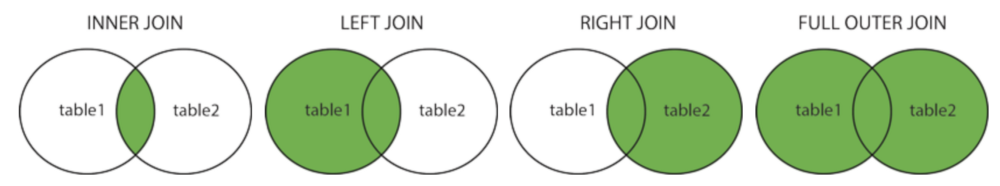

In [36]:
pd.merge(df_customer, df_info, on='id')

,id,name,age,city,company
0,1001,Dana Cohen,34,Tel Aviv,Alpha Ltd
1,1002,Yossi Levi,27,Haifa,Beta Inc
2,1003,Maya Katz,45,Jerusalem,Gamma Co
3,1004,Omer Ben-David,52,Beer Sheva,Delta Labs


In [37]:
pd.merge(df_customer, df_info, how='left', on='id')

,id,name,age,city,company
0,1001,Dana Cohen,34.0,Tel Aviv,Alpha Ltd
1,1002,Yossi Levi,27.0,Haifa,Beta Inc
2,1003,Maya Katz,45.0,Jerusalem,Gamma Co
3,1004,Omer Ben-David,52.0,Beer Sheva,Delta Labs
4,1005,Noa Friedman,NaN,NaN,NaN
5,1006,Amit Shapiro,NaN,NaN,NaN


Ids 1005 and 1006 have no match in `df_info`, so their `age`, `city` and `company` are missing (`NaN`).
Notice that `age` is now shown as `34.0`, a `float64` column: `NaN` is a floating-point value, so an integer column with missing values is stored as float.
If you need integers with missing values, use the nullable `Int64` dtype, for example `df_info.astype({'age': 'Int64'})`.

In [38]:
pd.merge(df_customer, df_info, how='left', on='id').dtypes

id           int64
name           str
age        float64
city           str
company        str
dtype: object

### Union

Assuming we have another store with it's clients as follow:

In [39]:
df_customer_1 = pd.DataFrame({
    'id':   [2001, 2002, 2003, 2004],
    'name': ['Lior Mizrahi', 'Tamar Peretz', 'Eitan Biton', 'Shira Azulay'],
})

In [40]:
df_customer_1

,id,name
0,2001,Lior Mizrahi
1,2002,Tamar Peretz
2,2003,Eitan Biton
3,2004,Shira Azulay


We want to combine the **rows** of both tables to one table, this is called union in SQL and concat in Python:

In [41]:
pd.concat([df_customer, df_customer_1])
#.loc[2], iloc[2]


,id,name
0,1001,Dana Cohen
1,1002,Yossi Levi
2,1003,Maya Katz
3,1004,Omer Ben-David
4,1005,Noa Friedman
5,1006,Amit Shapiro
0,2001,Lior Mizrahi
1,2002,Tamar Peretz
2,2003,Eitan Biton
3,2004,Shira Azulay


## Apply

 Manipulate columns and rows in a DataFrame with custom functions.

In [42]:
csv_url = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv'
df = pd.read_csv(csv_url)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


For the purpose of this exercise slice the dataframe from 'school' until the 'guardian' column

In [43]:
stud_alcoh = df.loc[: , "school":"guardian"]
stud_alcoh.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother
4,GP,F,16,U,GT3,T,3,3,other,other,home,father


Create a lambda function that will capitalize strings.

In [44]:
capitalizer = lambda x: x.capitalize()

Capitalize both Mjob and Fjob

In [45]:
stud_alcoh['Mjob'] = stud_alcoh['Mjob'].apply(capitalizer)
stud_alcoh['Fjob'] = stud_alcoh['Fjob'].apply(capitalizer)

In [46]:
stud_alcoh.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian
0,GP,F,18,U,GT3,A,4,4,At_home,Teacher,course,mother
1,GP,F,17,U,GT3,T,1,1,At_home,Other,course,father
2,GP,F,15,U,LE3,T,1,1,At_home,Other,other,mother
3,GP,F,15,U,GT3,T,4,2,Health,Services,home,mother
4,GP,F,16,U,GT3,T,3,3,Other,Other,home,father


Create a function called majority that returns a boolean value to a new column called legal_drinker (Consider majority as older than 17 years old)

In [47]:
def majority(x):
    if x > 17:
        return True
    else:
        return False

In [48]:
stud_alcoh['legal_drinker'] = stud_alcoh['age'].apply(majority)
stud_alcoh.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,legal_drinker
0,GP,F,18,U,GT3,A,4,4,At_home,Teacher,course,mother,True
1,GP,F,17,U,GT3,T,1,1,At_home,Other,course,father,False
2,GP,F,15,U,LE3,T,1,1,At_home,Other,other,mother,False
3,GP,F,15,U,GT3,T,4,2,Health,Services,home,mother,False
4,GP,F,16,U,GT3,T,3,3,Other,Other,home,father,False


Apply multiple columns

In [49]:
def f(x):
   return (x['G1'] + x['G2'] + x['G3']) / 3

In [50]:
df.apply(f, axis=1)

0       5.666667
1       5.333333
2       8.333333
3      14.666667
4       8.666667
         ...    
390     9.000000
391    15.333333
392     8.333333
393    11.000000
394     8.666667
Length: 395, dtype: float64

In [51]:
def f1(a, b, c):
   return (a + b + c) / 3

In [52]:
df.apply(lambda x: f1(x['G1'], x['G2'], x['G3']), axis=1)

0       5.666667
1       5.333333
2       8.333333
3      14.666667
4       8.666667
         ...    
390     9.000000
391    15.333333
392     8.333333
393    11.000000
394     8.666667
Length: 395, dtype: float64

In [53]:
df[['G1','G2','G3']].apply(lambda x: f1(*x), axis=1)

0       5.666667
1       5.333333
2       8.333333
3      14.666667
4       8.666667
         ...    
390     9.000000
391    15.333333
392     8.333333
393    11.000000
394     8.666667
Length: 395, dtype: float64

# Matplotlib

In [54]:
import matplotlib.pyplot as plt

By running this special iPython command, we will be displaying plots inline:

In [55]:
%matplotlib inline

## Plotting

In [56]:
lunch_tips = tips[tips.time == 'Lunch'].sort_values(by='total_bill')
lunch_tips.head()

,total_bill,tip,sex,smoker,day,time,size,new_calc,log_total
149,7.51,2.00,Male,No,Thur,Lunch,2,0.751,2.016235
195,7.56,1.44,Male,No,Thur,Lunch,2,0.756,2.022871
145,8.35,1.50,Female,No,Thur,Lunch,2,0.835,2.122262
135,8.51,1.25,Female,No,Thur,Lunch,2,0.851,2.141242
126,8.52,1.48,Male,No,Thur,Lunch,2,0.852,2.142416


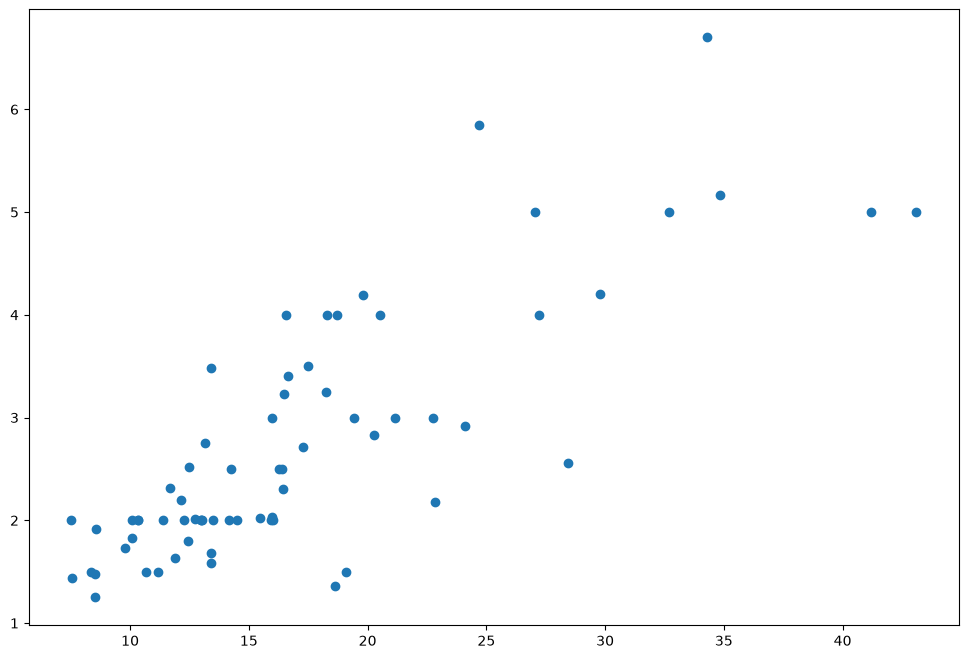

In [57]:
plt.figure(figsize=(12,8))
plt.scatter(lunch_tips['total_bill'], lunch_tips['tip'])

## Subplots

You can plot different things in the same figure using the subplot function. Here is an example:

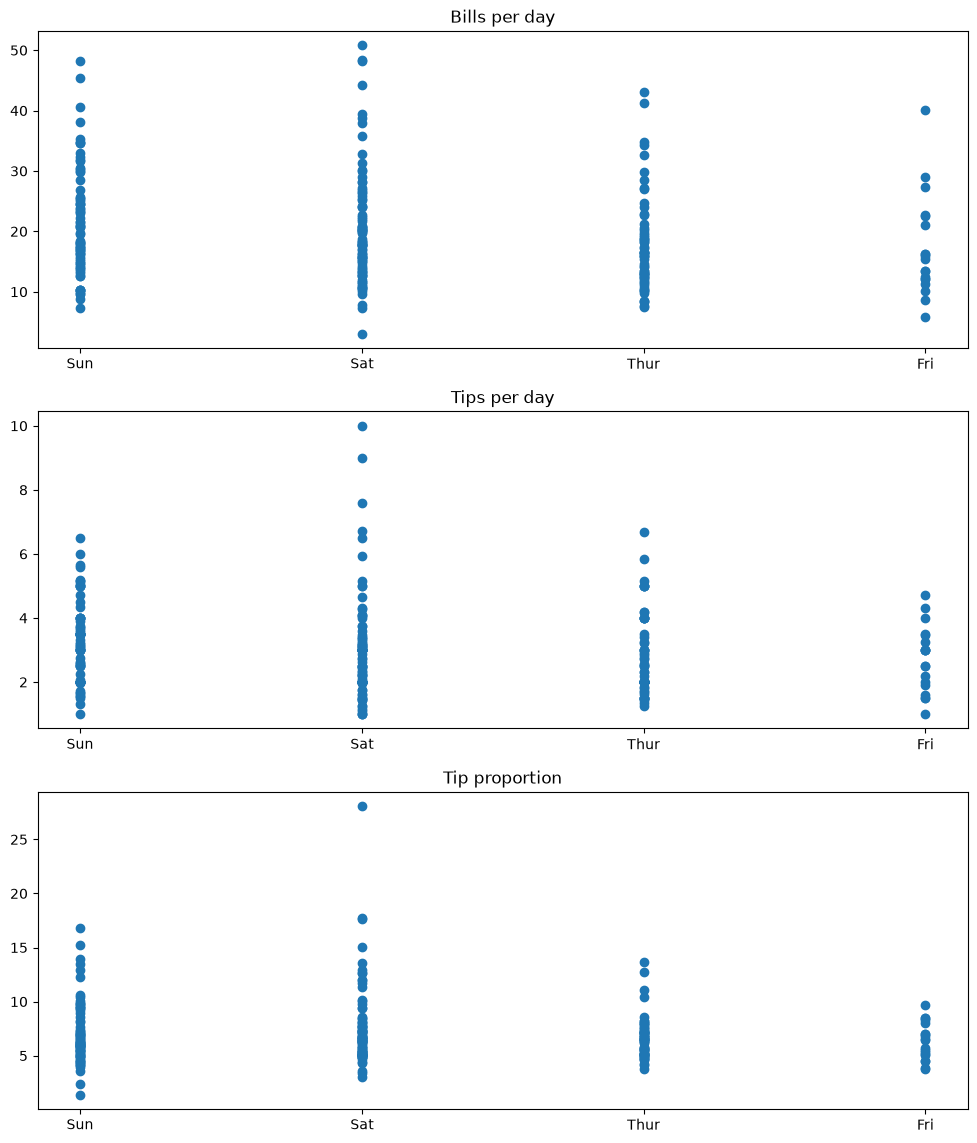

In [58]:
# A grid of 3 rows and 1 column; plt.subplot(3, 1, k) makes the k-th plot active.
plt.figure(figsize=(12,14))

# First plot
plt.subplot(3, 1, 1)
plt.scatter(tips['day'].astype(str), tips['total_bill'])
plt.title('Bills per day')

# Second plot
plt.subplot(3, 1, 2)
plt.scatter(tips['day'].astype(str), tips['tip'])
plt.title('Tips per day')

# Third plot
plt.subplot(3, 1, 3)
plt.scatter(tips['day'].astype(str), tips['total_bill'] / tips['tip'])
plt.title('Tip proportion')

# Show the figure.
plt.show()

You can read much more about the `subplot` function in the [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html).